# Lab 2 - Advanced Data Analysis of Soil Water Retention Curves
**Scientific Programming (MAPC24) - Master in Automation and Industrial Control, ITM**

**Student:** Santiago Cano Molina
**Semester:** 2026-2

# Brief context

Soil holds its water more strongly as it gets drier. This strength is the matric potential, $\psi$. My thesis proposal is to estimate $\psi$ with a machine learning model. The model combines a high-frequency electromagnetic signal with soil properties (texture, bulk density). It would be a cheaper alternative to tensiometers and would help with irrigation decisions.

The sensor does not exist yet. So, as in Lab 1, I use a public dataset on the topic: the Global Soil Hydraulic Properties database (GSHP; Gupta et al., 2022), under CC BY 4.0. It has 15,259 soil water characteristic curves measured in the laboratory. Each curve is a set of points: matric potential $\psi$ (meters of water) against volumetric water content $\theta$ (m$^3$/m$^3$). The file also has site descriptors, such as the USDA texture class. Every row is one point, so a curve uses several rows. I keep only tropical soils, because the thesis system will be tested in the tropics.

In this lab every curve is one sample, and its texture group (*coarse*, *medium* or *fine*) is its class. My question is: which features of a curve change with texture, and how well can I tell the groups apart? This matters because the same electrical signal can mean different water contents in a sandy and in a clayey soil. If the curves differ by texture, the future model needs texture as an input. In this lab I use texture only as a label, to measure how different the curves are.

# Advanced data handling with Pandas

In this section I turn the raw file into a table with one row per curve. A curve is the unit of analysis for the rest of the lab. I work in two stages. First I clean the points (the rows of the file). Then I group them into curves. After every filter I record how many rows and curves remain, so I can trace each decision.

## Loading the data

As in Lab 1, I read the file from my GitHub repository. The file uses the `latin-1` encoding, so I pass it to `pd.read_csv`. Without it, pandas fails on accented characters in some site names. I also use `low_memory=False`, so pandas reads the whole file before it guesses the type of each column. This avoids mixed-type warnings in a file with 54 columns.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
from scipy.stats import shapiro, f_oneway, kruskal
from sklearn.metrics import roc_auc_score

DATA_URL = (
    "https://raw.githubusercontent.com/santiagocano298366/"
    "scientific-programming-labs-2026-2/main/"
    "data_raw/WRC_dataset_surya_et_al_2021_final.csv"
)

raw = pd.read_csv(DATA_URL, encoding="latin-1", low_memory=False)
print(raw.shape)

(136989, 54)


## Cleaning the points

Each filter below removes rows that cannot be trusted as a measurement of a retention curve. After each filter I print the number of rows and of distinct curves (`layer_id`).

- `drop_duplicates()` removes rows that are identical in every column.
- `data_flag == "good quality estimate"` keeps the curves where the authors' van Genuchten fit was well defined (alpha and n not at the edge of the allowed range). It is a flag of the fit, not of the measurement. Because of this, it can change the mix of textures (see the limitations at the end).
- `dropna(subset=...)` removes points that lack water content or potential, since a point needs both.
- $\psi \le 100{,}000$ m removes physically implausible potentials (the largest ones come from a single source).
- The physical check confirms $0 \le \theta \le 1$ and $\psi \ge 0$. It removes nothing here, but I keep it as a guard.
- `climate_classes == "Tropical"` keeps the soils that match the thesis site.

In [2]:
print("raw file:", len(raw), "rows,", raw["layer_id"].nunique(), "curves")

points = raw.drop_duplicates()
print("without duplicate rows:", len(points), "rows,", points["layer_id"].nunique(), "curves")

points = points[points["data_flag"] == "good quality estimate"]
print("only good quality fits:", len(points), "rows,", points["layer_id"].nunique(), "curves")

points = points.dropna(subset=["lab_wrc", "lab_head_m"])
print("without missing values:", len(points), "rows,", points["layer_id"].nunique(), "curves")

points = points[points["lab_head_m"] <= 100000]
print("without psi > 100,000 m:", len(points), "rows,", points["layer_id"].nunique(), "curves")

physical_ok = (points["lab_wrc"] >= 0) & (points["lab_wrc"] <= 1) & (points["lab_head_m"] >= 0)
print("rows outside the physical range (theta in [0, 1], psi >= 0):", (~physical_ok).sum())
points = points[physical_ok]

tropical = points[points["climate_classes"] == "Tropical"]
print("tropical only:", len(tropical), "rows,", tropical["layer_id"].nunique(), "curves")

raw file: 136989 rows, 15259 curves


without duplicate rows: 132447 rows, 15259 curves
only good quality fits: 112708 rows, 11705 curves
without missing values: 112703 rows, 11705 curves
without psi > 100,000 m: 112652 rows, 11705 curves
rows outside the physical range (theta in [0, 1], psi >= 0): 0
tropical only: 10322 rows, 1122 curves


## Texture classes

The label of each curve is its USDA texture class (`tex_psda`). There are twelve classes, and some have too few curves to compare. So I merge them into three groups by sand, silt and clay content: *coarse* (sandy soils), *medium* (loamy and silty soils) and *fine* (clayey soils). First I look at the values of the column.

`value_counts(dropna=False)` counts how many rows each value has. With `dropna=False` it also counts missing values, so I can see how many rows have no texture.

In [3]:
tropical["tex_psda"].value_counts(dropna=False)

tex_psda
sand               4010
clay               1845
sandy loam         1175
sandy clay loam     881
NaN                 713
loamy sand          502
sandy clay          288
clay loam           243
silt loam           181
silty clay loam     138
silt                107
loam                102
silty clay           72
Error                65
Name: count, dtype: int64

Two things in this output need a decision. Some rows have no texture (`NaN`) and others have the value `"Error"`. I cannot assign either to a group, so I drop them.

I write the grouping as a dictionary and apply it with `.map`. This replaces each value with the one in the dictionary. A value that is not in the dictionary (such as `"Error"`) becomes `NaN`, and `dropna` removes it. So one filter covers both cases, and the grouping is easy to read in the code.

In [4]:
texture_group_map = {
    "sand": "coarse", "loamy sand": "coarse", "sandy loam": "coarse",
    "sandy clay loam": "medium", "loam": "medium", "silt loam": "medium",
    "silt": "medium", "silty clay loam": "medium", "clay loam": "medium",
    "clay": "fine", "sandy clay": "fine", "silty clay": "fine",
}

labelled = tropical.copy()
labelled["texture_group"] = labelled["tex_psda"].map(texture_group_map)
print("rows without a texture group:", labelled["texture_group"].isna().sum())

labelled = labelled.dropna(subset=["texture_group"])
print("with a valid texture:", len(labelled), "rows,", labelled["layer_id"].nunique(), "curves")

rows without a texture group: 778


with a valid texture: 9544 rows, 1044 curves


## From points to curves

The cleaned table still has one row per measured point. I need one row per curve. So I group by `layer_id` with `groupby` and summarize each group with `.agg`. The `agg` function takes named outputs in the form `new_name=(column, function)`.

For every curve I keep the number of points (`size`) and the smallest and largest potential (`min`, `max`). I also keep the texture group, the site (`profile_id`) and the source (`reference`) with `first`. These three do not change inside a curve, so the first value is the right one. I also keep the `alpha` and `n` fitted by the database authors, as `alpha_csv` and `n_csv`. In Section 3 I use them to check my own fit.

In [5]:
curve_table = labelled.groupby("layer_id").agg(
    n_points=("lab_head_m", "size"),
    psi_min=("lab_head_m", "min"),
    psi_max=("lab_head_m", "max"),
    texture_group=("texture_group", "first"),
    profile_id=("profile_id", "first"),
    reference=("reference", "first"),
    alpha_csv=("alpha", "first"),
    n_csv=("n", "first"),
)
curve_table.head()

,n_points,psi_min,psi_max,texture_group,profile_id,reference,alpha_csv,n_csv
layer_id,,,,,,,,
598005,4,3.3,150.0,medium,52198,Bates_et_al_2020,0.498733,1.781269
598009,5,1.0,150.0,medium,52198,Bates_et_al_2020,42.196219,1.092612
598061,4,3.3,150.0,fine,52258,Bates_et_al_2020,10.906402,1.206480
598431,4,1.0,150.0,coarse,53561,Bates_et_al_2020,4.552414,1.804189
598449,4,1.0,150.0,coarse,53564,Bates_et_al_2020,3.294492,1.583100


## Selecting usable curves

A curve is useful for feature extraction only if it covers the range I measure. Section 3 reads the water content between 1 m and 100 m of potential. This is the range that matters for irrigation. So I keep only the curves that:

- have at least 6 points, so the shape can be described and a 4-parameter model can be fitted;
- start at 1 m or less (`psi_min <= 1`);
- reach 100 m or more (`psi_max >= 100`). In Lab 1 I used 153 m as the wilting point; here I stop at 100 m, a round value, so I do not require curves to reach 153 m.

The first rows of `curve_table` show why. Several curves have 4 or 5 points, and some start at 3.3 m. For those, a value at 1 m would have to be extrapolated, not read.

I join the three conditions with `&`. Each one goes in parentheses because `&` is evaluated before the comparisons. Then `isin` keeps the points of the selected curves.

In [6]:
usable = curve_table[
    (curve_table["n_points"] >= 6)
    & (curve_table["psi_min"] <= 1)
    & (curve_table["psi_max"] >= 100)
]

selected_points = labelled[labelled["layer_id"].isin(usable.index)]
print("selected curves:", len(usable), "with", len(selected_points), "rows")

selected curves: 940 with 9053 rows


## Flagging curves with an upward jump

Water content should not increase as the potential increases (the soil gets drier). If a curve rises noticeably, that is probably a measurement or recording problem. I do not remove these curves, because I cannot be sure they are wrong. I only flag them, and I keep them in the analysis.

I sort the points of each curve by potential. Then I take the difference between consecutive water contents with `groupby(...).diff()` (the first point of every curve gets `NaN`). I flag a curve if any difference is larger than 0.05 m$^3$/m$^3$. I chose 0.05 because smaller rises are normal measurement noise.

In [7]:
selected_points = selected_points.sort_values(["layer_id", "lab_head_m"])
water_content_change = selected_points.groupby("layer_id")["lab_wrc"].diff()

has_upward_jump = (water_content_change > 0.05).groupby(selected_points["layer_id"]).any()
usable = usable.assign(has_upward_jump=has_upward_jump)

print("curves flagged with an upward jump larger than 0.05:", usable["has_upward_jump"].sum(), "of", len(usable))

curves flagged with an upward jump larger than 0.05: 4 of 940


## Curve data and overview

Section 3 needs the potentials and water contents of each curve as arrays. I store them in a dictionary. The key is `layer_id` and the value is the pair `(psi, theta)`. Iterating over `groupby` gives the sub-table of each curve, and `.values` turns a column into a NumPy array.

I also define the group order and one color per group here, so all later figures use the same ones. The figure shows how many curves each group has, and all selected curves together. I also print how many curves of each group come from each source (`reference`), because I use it in the discussion.

In [8]:
curve_data = {
    layer_id: (sub["lab_head_m"].values, sub["lab_wrc"].values)
    for layer_id, sub in selected_points.groupby("layer_id")
}

group_order = ["coarse", "medium", "fine"]
group_colors = {"coarse": "#E69F00", "medium": "#009E73", "fine": "#0072B2"}

print(usable["texture_group"].value_counts()[group_order])
print("sites:", usable["profile_id"].nunique(), "| references:", usable["reference"].nunique())
print(pd.crosstab(usable["reference"], usable["texture_group"])[group_order])

texture_group
coarse    538
medium    170
fine      232
Name: count, dtype: int64
sites: 270 | references: 8
texture_group        coarse  medium  fine
reference                                
Cooper_et_al_2017        16       0     0
Grunwald_2020           445      52     2
Konyai_et_al_2006         4       1     0
Leenaars_et_al_2014      61      68    54
Medina_et_al_2002         0       0     1
Oliveira et al_2019       0       1     0
Ottoni_et_al_2018        12      47   175
Thakur_et_al_2007         0       1     0


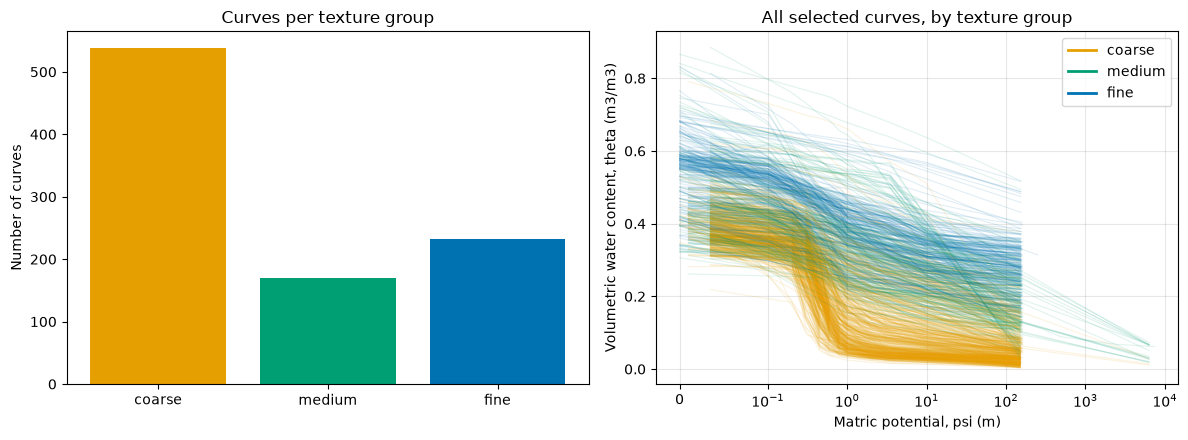

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

counts = usable["texture_group"].value_counts()[group_order]
axes[0].bar(counts.index, counts.values, color=[group_colors[g] for g in counts.index])
axes[0].set_ylabel("Number of curves")
axes[0].set_title("Curves per texture group")

for layer_id, (psi, theta) in curve_data.items():
    group = usable.loc[layer_id, "texture_group"]
    axes[1].plot(psi, theta, color=group_colors[group], alpha=0.12, linewidth=0.8)
for group in group_order:
    axes[1].plot([], [], color=group_colors[group], linewidth=2, label=group)
axes[1].set_xscale("symlog", linthresh=0.1)
axes[1].set_xlabel("Matric potential, psi (m)")
axes[1].set_ylabel("Volumetric water content, theta (m3/m3)")
axes[1].set_title("All selected curves, by texture group")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

# Feature extraction using OOP

I turn each curve into a vector of numbers with three feature domains. They are candidate features, because they are standard reference quantities in soil physics. I still have to validate them with my thesis advisor.

| Domain | Features | What they describe |
|---|---|---|
| Retention level (amplitude) | $\theta$ at 1, 3.3, 10, 33 and 100 m; area under $\theta$ vs $\log_{10}\psi$ between 1 and 100 m | How much water the soil holds at reference potentials. 3.3 m is about 33 kPa, the usual field capacity. The area summarizes the whole working range. |
| Curve shape | largest slope $\lvert d\theta/d\log_{10}\psi\rvert$, where it happens, mean slope in the dry half (10-100 m) | How fast the soil releases water. It is related to the pore-size distribution. |
| Van Genuchten parameters | $\log_{10}\alpha$, $n$, $\theta_r$, $\theta_s$ | A model-based description: air-entry scale, steepness, residual and saturated water content. |

The first two domains are model-free: I compute them directly on the measured points. The third is model-based, because it depends on a fitted equation. The curves are not signals in time, so I do not use a frequency domain.

## Base classes

The design has three layers. A `SoilRetentionCurve` object holds one curve. Two small tools come from the numerical computation session: `Trapezoidal` integrates a function and `CentralDiff` differentiates it. Then one extractor class per domain takes a curve and returns its features.

The curve class has two lookup methods. `theta_at` gives the water content at any potential by linear interpolation (`np.interp`) between the measured points. `theta_at_log` does the same, but it receives $\log_{10}\psi$. I use it because the curve covers several orders of magnitude, so the integral and the slope make more sense per decade of potential than per meter. The integrator and the derivative receive a function, so they can work directly on `theta_at_log`.

In [10]:
class SoilRetentionCurve:
    def __init__(self, layer_id, psi, theta):
        order = np.argsort(psi)
        self.layer_id = layer_id
        self.psi = np.array(psi)[order]
        self.theta = np.array(theta)[order]

    def theta_at(self, psi_values):
        return np.interp(psi_values, self.psi, self.theta)

    def theta_at_log(self, log_psi):
        return self.theta_at(10 ** np.asarray(log_psi))


class Integrator:
    def __init__(self, a, b, n):
        self.a, self.b, self.n = a, b, n
        self.points, self.weights = self.construct_method()

    def construct_method(self):
        pass

    def integrate(self, f):
        return self.weights @ f(self.points)


class Trapezoidal(Integrator):
    def construct_method(self):
        h = (self.b - self.a) / (self.n - 1)
        w = h * np.ones(self.n)
        w[0] = w[-1] = h / 2
        x = np.linspace(self.a, self.b, self.n)
        return x, w


class Derivative:
    def __init__(self, func, h=1e-4):
        self.func = func
        self.h = h


class CentralDiff(Derivative):
    def __call__(self, x):
        return (self.func(x + self.h) - self.func(x - self.h)) / (2 * self.h)

## Van Genuchten model

The van Genuchten model and its fitting class come from Lab 1, with two changes. The fit now has bounds ($\alpha \in [10^{-3}, 10^{3}]$, $n \in [1.01, 10]$, $\theta_r \in [0, 0.5]$, $\theta_s \in [0.2, 1]$) With the bounds, no curve gives an impossible parameter set or a failed fit. The class can also report its own RMSE.

The van Genuchten (1980) model describes the whole curve with four numbers:

$$\theta(\psi) = \theta_r + \frac{\theta_s - \theta_r}{\left[1 + (\alpha\psi)^n\right]^{m}}, \qquad m = 1 - \frac{1}{n}$$

where $\theta_r$ and $\theta_s$ are the residual and saturated water content, $\alpha$ is related to the potential where air enters the largest pores, and $n$ controls how steeply the curve drops. `curve_fit` finds the four values that minimize the squared error against the measured points. It needs a starting guess (`p0`). I start from $\alpha = 1$ and $n = 1.5$, and I take $\theta_r$ and $\theta_s$ from the smallest and largest measured water contents.

In [11]:
def van_genuchten(psi, alpha, n, theta_r, theta_s):
    m = 1 - 1 / n
    return theta_r + (theta_s - theta_r) / (1 + (alpha * psi) ** n) ** m


class VanGenuchtenModel:
    def __init__(self):
        self.params = None

    def fit(self, curve):
        p0 = [1.0, 1.5, min(curve.theta.min(), 0.4), max(curve.theta.max(), 0.3)]
        lower = [1e-3, 1.01, 0.0, 0.2]
        upper = [1e3, 10.0, 0.5, 1.0]
        self.params, _ = curve_fit(van_genuchten, curve.psi, curve.theta,
                                   p0=p0, bounds=(lower, upper), maxfev=10000)
        return self

    def __call__(self, psi):
        return van_genuchten(psi, *self.params)

    def rmse(self, curve):
        return np.sqrt(np.mean((curve.theta - self(curve.psi)) ** 2))

## Feature extractors

All extractors share one interface. The base class `FeatureExtractor` has a `domain` name, a list of feature `names` and an `extract(curve)` method that returns a dictionary `{feature name: value}`. Each domain is a subclass that fills in these three things. To add a new domain, I only write one more subclass.

- `RetentionLevelFeatures` evaluates $\theta$ with `np.interp` at the reference potentials. It integrates $\theta$ over $\log_{10}\psi\in[0,2]$ (1 m to 100 m) with `Trapezoidal(0, 2, 201)`. The 201 points give a step of 0.01 decades.
- `ShapeFeatures` differentiates $\theta$ with respect to $\log_{10}\psi$ using a central difference with a step of 0.05 decades. I use the logarithm because the slope per decade is the meaningful quantity. The slope is negative everywhere, so I take the absolute value.
- `VanGenuchtenFeatures` fits the four parameters and returns $\log_{10}\alpha$ instead of $\alpha$. The value of $\alpha$ varies over orders of magnitude, and the logarithm makes its distribution usable for statistics. The extractor also stores the fit RMSE, but only as a quality indicator and not as a feature.

The table needs one pass over the curves, so it is $O(N)$. The van Genuchten fit is the slowest part.

In [12]:
class FeatureExtractor:
    domain = "base"
    names = []

    def extract(self, curve):
        pass


class RetentionLevelFeatures(FeatureExtractor):
    domain = "retention level"
    psi_reference = [1, 3.3, 10, 33, 100]
    names = ["theta_1m", "theta_3p3m", "theta_10m", "theta_33m", "theta_100m", "area_theta_logpsi"]

    def extract(self, curve):
        values = list(curve.theta_at(self.psi_reference))
        area = Trapezoidal(0, 2, 201).integrate(curve.theta_at_log)
        return dict(zip(self.names, values + [area]))


class ShapeFeatures(FeatureExtractor):
    domain = "curve shape"
    names = ["max_abs_slope", "log_psi_at_max_slope", "mean_abs_slope_dry"]

    def extract(self, curve):
        slope = CentralDiff(curve.theta_at_log, h=0.05)
        grid = np.linspace(0.05, 1.95, 191)
        steepness = np.abs(slope(grid))
        return {
            "max_abs_slope": steepness.max(),
            "log_psi_at_max_slope": grid[steepness.argmax()],
            "mean_abs_slope_dry": steepness[grid >= 1].mean(),
        }


class VanGenuchtenFeatures(FeatureExtractor):
    domain = "van Genuchten parameters"
    names = ["log10_alpha", "n", "theta_r", "theta_s"]

    def extract(self, curve):
        model = VanGenuchtenModel().fit(curve)
        alpha, n, theta_r, theta_s = model.params
        return {"log10_alpha": np.log10(alpha), "n": n, "theta_r": theta_r,
                "theta_s": theta_s, "vg_fit_rmse": model.rmse(curve)}

## Feature table

I apply the three extractors to every curve. For each curve I create a `SoilRetentionCurve` and collect the dictionary of each extractor into one row. At the end I turn the rows into a DataFrame indexed by `layer_id`.

`domains` stores the list of feature names of each extractor, and `feature_cols` is the flat list of the 13 features. The final `dataset` joins the features with the texture group, the site (`profile_id`), the data source (`reference`) and the jump flag of each curve. The site is needed in Section 5 to split the data without leaking information. The source is used to discuss limitations.

In [13]:
extractors = [RetentionLevelFeatures(), ShapeFeatures(), VanGenuchtenFeatures()]

rows = []
for layer_id, (psi, theta) in curve_data.items():
    curve = SoilRetentionCurve(layer_id, psi, theta)
    row = {"layer_id": layer_id}
    for extractor in extractors:
        row.update(extractor.extract(curve))
    rows.append(row)
feature_table = pd.DataFrame(rows).set_index("layer_id")

domains = {extractor.domain: extractor.names for extractor in extractors}
feature_cols = []
for names in domains.values():
    feature_cols += names

dataset = feature_table.join(usable[["texture_group", "profile_id", "reference", "has_upward_jump"]])
print("curves x columns:", dataset.shape)
print("missing values in the feature columns:", int(dataset[feature_cols].isna().sum().sum()))
dataset.head()

curves x columns: (940, 18)
missing values in the feature columns: 0


,theta_1m,theta_3p3m,theta_10m,theta_33m,theta_100m,area_theta_logpsi,max_abs_slope,log_psi_at_max_slope,mean_abs_slope_dry,log10_alpha,n,theta_r,theta_s,vg_fit_rmse,texture_group,profile_id,reference,has_upward_jump
layer_id,,,,,,,,,,,,,,,,,,
BJ wasp_1_2,0.105,0.080278,0.073345,0.069265,0.057377,0.151173,0.090711,0.25,0.014868,0.739464,2.439604,6.509566e-02,0.416654,0.010246,coarse,BJ wasp_1,Leenaars_et_al_2014,False
BJ wasp_1_3,0.120,0.093976,0.086709,0.084895,0.079612,0.181201,0.094834,0.25,0.006608,0.720271,2.637401,8.603917e-02,0.426708,0.007640,coarse,BJ wasp_1,Leenaars_et_al_2014,False
BJ wasp_1_6,0.246,0.220069,0.210491,0.207317,0.198071,0.428866,0.090711,0.25,0.011564,0.708470,1.618358,1.890851e-01,0.346955,0.002161,fine,BJ wasp_1,Leenaars_et_al_2014,False
BJ wasp_3_1,0.496,0.476161,0.462866,0.449566,0.410822,0.922906,0.118932,1.95,0.048458,0.838654,1.054418,6.864610e-15,0.558136,0.004919,fine,BJ wasp_3,Leenaars_et_al_2014,False
BJ wasp_3_3,0.510,0.481556,0.467424,0.457600,0.428982,0.938442,0.094834,0.25,0.035793,0.738806,1.165816,3.213362e-01,0.578021,0.003203,fine,BJ wasp_3,Leenaars_et_al_2014,False


## Sanity checks

I make two checks before using the features. First, I look at one curve of each group. The retention-level features must decrease as $\psi$ grows, because water content cannot rise as the soil dries. The coarse curve must also hold the least water. Second, I compare my van Genuchten fit with the parameters published in the CSV.

In [14]:
example_ids = [dataset[dataset["texture_group"] == g].index[0] for g in group_order]
dataset.loc[example_ids, feature_cols + ["texture_group"]].T

layer_id,BJ wasp_1_2,CD wasp_1_3,BJ wasp_1_6
theta_1m,0.105,0.192,0.246
theta_3p3m,0.080278,0.178766,0.220069
theta_10m,0.073345,0.167545,0.210491
theta_33m,0.069265,0.158477,0.207317
theta_100m,0.057377,0.132061,0.198071
area_theta_logpsi,0.151173,0.334803,0.428866
max_abs_slope,0.090711,0.08109,0.090711
log_psi_at_max_slope,0.25,1.95,0.25
mean_abs_slope_dry,0.014868,0.03304,0.011564
log10_alpha,0.739464,1.490245,0.70847


In [15]:
fit_check = usable.join(dataset[["log10_alpha", "n"]])
print("correlation of log10(alpha): fitted here vs published in the CSV:",
      round(np.corrcoef(fit_check["log10_alpha"], np.log10(fit_check["alpha_csv"]))[0, 1], 3))
print("correlation of n: fitted here vs published in the CSV:",
      round(np.corrcoef(fit_check["n_csv"], fit_check["n"])[0, 1], 3))
print("median RMSE of the van Genuchten fit (m3/m3):", round(dataset["vg_fit_rmse"].median(), 4))
at_lower_bound = dataset["theta_r"] < 1e-6
print("fits with theta_r on its lower bound (< 1e-6):", int(at_lower_bound.sum()))
print("theta_r on its lower bound, by group:", at_lower_bound.groupby(dataset["texture_group"]).sum()[group_order].to_dict())

correlation of log10(alpha): fitted here vs published in the CSV: 0.999
correlation of n: fitted here vs published in the CSV: 1.0
median RMSE of the van Genuchten fit (m3/m3): 0.0082
fits with theta_r on its lower bound (< 1e-6): 152
theta_r on its lower bound, by group: {'coarse': 47, 'medium': 76, 'fine': 29}


Both checks pass. The three example curves behave as expected: each $\theta$ column decreases with $\psi$, and the water held grows from coarse to fine. My fitted $\log_{10}\alpha$ and $n$ are almost identical to the published values (correlations of about 0.999 and 1.0). The median RMSE is under 0.01 m$^3$/m$^3$.

One limitation: 152 of the 940 fits (16%) have $\theta_r$ on its lower bound of 0. They are not evenly spread: 76 of 170 medium curves (45%), against 47 of 538 coarse (9%) and 29 of 232 fine (12.5%). This happens when the measured points do not reach the dry end enough to determine the residual water content. So $\theta_r$ is the least reliable parameter. I keep these fits. But part of the difference in $\theta_r$ between medium and the other groups may come from the fit and not from the soil, so I do not rely on $\theta_r$ alone.

Why these features matter for the research problem:

- Retention level. The electromagnetic signal responds to the amount of water. The sensor must turn that amount into a matric potential. If two textures hold very different amounts of water at the same potential, one calibration for all soils cannot work.
- Curve shape. The slope is how much $\theta$ changes for a small change in $\psi$. It shows where the sensor needs the most precision, as discussed in Lab 1. Where the curve is flat, a small error in the signal gives a large error in potential. The curves are interpolated linearly, so this domain is the least precise.
- Van Genuchten parameters. They describe a curve with four numbers that have physical meaning. They are also the natural output of the laboratory reference measurements that the final system must reproduce.

# Statistical analysis of custom data

The analysis has four steps: (1) summary statistics and distributions per group, (2) outliers, (3) normality tests that decide between ANOVA and Kruskal-Wallis, and (4) separability of single features with Fisher's discriminant ratio (FDR) and the AUC. Feature sets are compared in the next section. The groups are *coarse*, *medium* and *fine* texture.

## Summary statistics

I group the dataset by texture group with `groupby`. For the 13 features I compute the mean, the median and the variance of each group. If the mean and the median differ, the distribution is skewed. The variance shows how spread out each group is.

In [16]:
by_group = dataset.groupby("texture_group")[feature_cols]

print("MEAN")
display(by_group.mean().loc[group_order].T.round(3))
print("MEDIAN")
display(by_group.median().loc[group_order].T.round(3))
print("VARIANCE")
display(by_group.var().loc[group_order].T.round(4))

MEAN


texture_group,coarse,medium,fine
theta_1m,0.168,0.349,0.384
theta_3p3m,0.130,0.315,0.350
theta_10m,0.123,0.294,0.319
theta_33m,0.113,0.271,0.308
theta_100m,0.087,0.219,0.290
area_theta_logpsi,0.248,0.585,0.660
max_abs_slope,0.132,0.201,0.133
log_psi_at_max_slope,0.665,1.271,0.881
mean_abs_slope_dry,0.034,0.072,0.029
log10_alpha,0.434,0.488,0.896


MEDIAN


texture_group,coarse,medium,fine
theta_1m,0.138,0.330,0.389
theta_3p3m,0.096,0.298,0.345
theta_10m,0.088,0.283,0.318
theta_33m,0.080,0.259,0.306
theta_100m,0.062,0.212,0.291
area_theta_logpsi,0.183,0.558,0.658
max_abs_slope,0.104,0.150,0.122
log_psi_at_max_slope,0.250,1.650,0.740
mean_abs_slope_dry,0.022,0.048,0.022
log10_alpha,0.416,0.666,0.921


VARIANCE


texture_group,coarse,medium,fine
theta_1m,0.0123,0.0128,0.0065
theta_3p3m,0.0099,0.0121,0.0062
theta_10m,0.0091,0.0120,0.0058
theta_33m,0.0077,0.0099,0.0057
theta_100m,0.0050,0.0059,0.0051
area_theta_logpsi,0.0348,0.0421,0.0229
max_abs_slope,0.0093,0.0238,0.0048
log_psi_at_max_slope,0.5778,0.5354,0.3314
mean_abs_slope_dry,0.0012,0.0046,0.0007
log10_alpha,0.0873,0.4786,0.1297


The means follow the physics. The dry-end water content $\theta_{100m}$ grows from 0.087 (coarse) to 0.219 (medium) and 0.290 (fine). The area under the curve grows from 0.25 to 0.59 and 0.66. The medium and fine groups are close in most amplitude features, and the coarse group is far from both.

Two details matter for what comes next. First, in several features the mean is larger than the median (for example $\theta_{1m}$ in the coarse group: 0.168 against 0.138). This means the distributions are skewed to the right. Second, the variances are very different between groups. The variance of $n$ is 1.93 in the coarse group and 0.17 in the medium group, more than ten times larger. ANOVA assumes normal groups with equal variance, so skewed groups with unequal variances may not fit it. I test normality below.

## Distributions per group

A table of means hides the shape of the data. The density plots (`sns.kdeplot`) draw a smoothed histogram per group. There is one panel per feature and one figure per domain. I use `common_norm=False` so each group is normalized on its own and a small group does not look flatter than a large one.

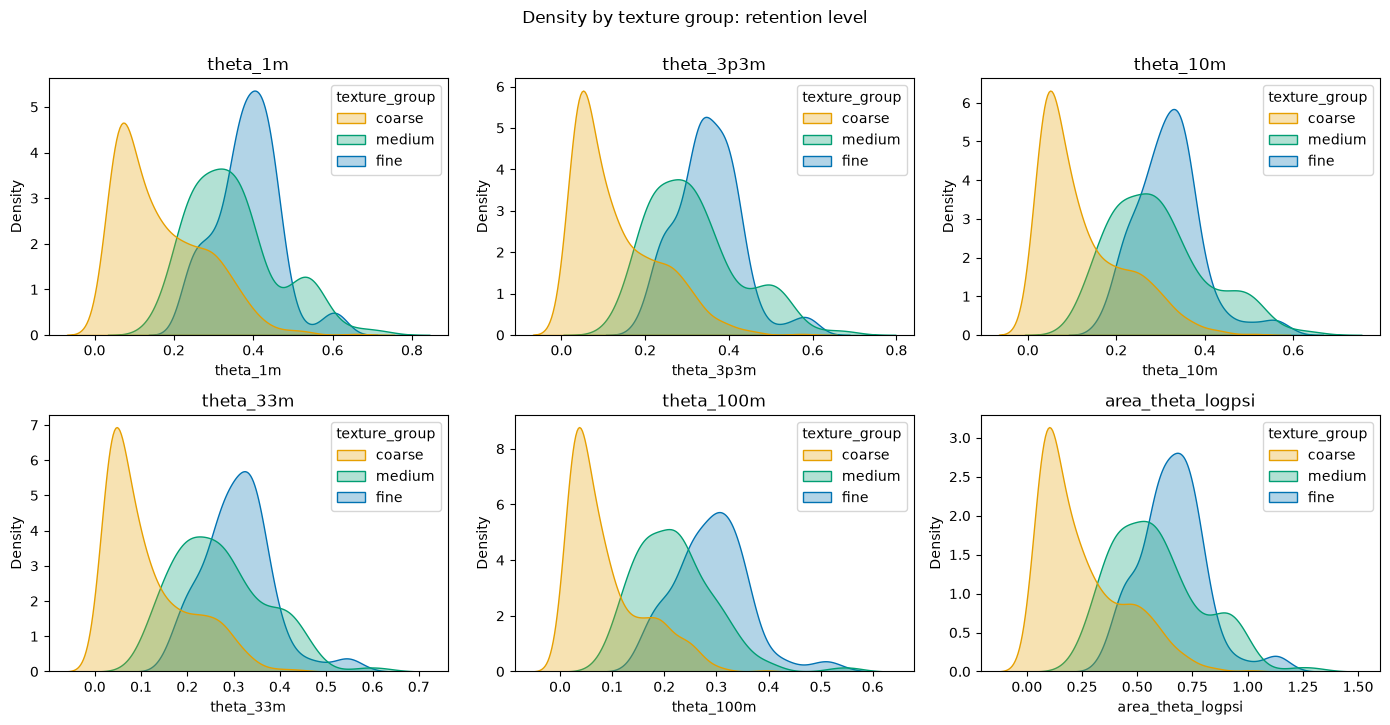

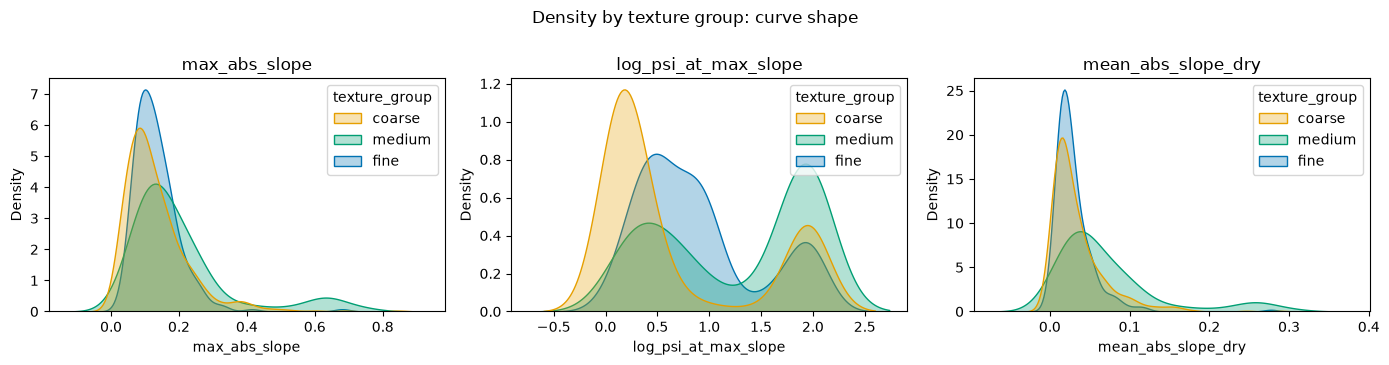

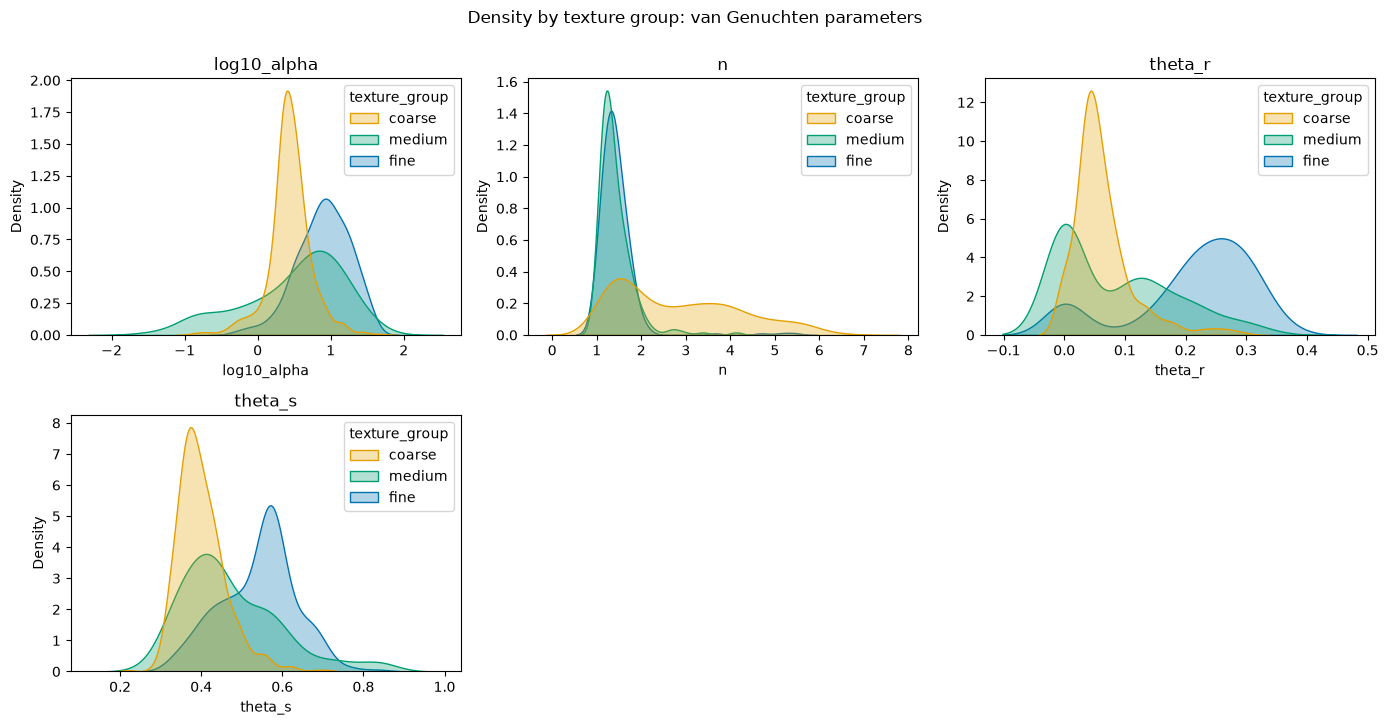

In [17]:
def plot_domain(domain_name, columns):
    n_rows = (len(columns) + 2) // 3
    plt.figure(figsize=(14, 3.6 * n_rows))
    for i, feature in enumerate(columns):
        plt.subplot(n_rows, 3, i + 1)
        sns.kdeplot(data=dataset, x=feature, hue="texture_group", hue_order=group_order,
                    palette=group_colors, common_norm=False, fill=True, alpha=0.3, linewidth=1)
        plt.title(feature)
    plt.suptitle("Density by texture group: " + domain_name, y=1.0)
    plt.tight_layout()
    plt.show()

for domain_name, columns in domains.items():
    plot_domain(domain_name, columns)

*Retention level.* The coarse group forms its own peak at low water content, with a long tail to the right. The medium and fine groups overlap a lot, and the fine group is narrower and sits to the right. This agrees with the numbers above: coarse is easy to separate from the others, and medium and fine are not. The separation is clearest at the dry end ($\theta_{100m}$), where the three peaks are farthest apart.

*Van Genuchten parameters.* The parameter $n$ separates coarse from the rest in a different way. Medium and fine have almost the same narrow peak around 1.3, and the coarse group spreads from about 1 to 7. $\theta_r$ and $\theta_s$ are higher for fine soils. The density plots go below zero for $\theta_r$, which is impossible. Part of this is the smoothing of the plot, and part is that many fits sit exactly at 0 (see Section 3).

*Curve shape.* The three groups almost coincide in `max_abs_slope` and `mean_abs_slope_dry`, so these features carry little information. `log_psi_at_max_slope` takes only 24 different values, and 43% of the curves sit at 0.25 or 1.95. I differentiate a piecewise-linear curve, so the steepest point depends on where the laboratory points are and not only on the soil. I treat it as a weak feature.

## Outliers

I detect outliers within each texture group with the 1.5 IQR rule. A value is flagged if it lies more than 1.5 IQR below the first quartile or above the third quartile of its own group. Doing it by group avoids flagging a fine soil only because it differs from the coarse ones.

I loop over the three groups. In each one I compute the quartiles of every feature and compare each curve with the limits of its own group. I only count and flag the outliers. I do not remove them, because in soils a large value can be a real property of the sample and not an error.

In [18]:
is_outlier = pd.DataFrame(False, index=dataset.index, columns=feature_cols)
for group in group_order:
    in_group = dataset["texture_group"] == group
    values = dataset.loc[in_group, feature_cols]
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    is_outlier.loc[in_group] = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)

outlier_table = pd.DataFrame({"outliers": is_outlier.sum(), "share (%)": (100 * is_outlier.mean()).round(1)})
display(outlier_table)

features_flagged = is_outlier.sum(axis=1)
print("curves flagged in at least one feature:", (features_flagged >= 1).sum(), "of", len(dataset))
print("curves flagged in three or more features:", (features_flagged >= 3).sum())

,outliers,share (%)
theta_1m,16,1.7
theta_3p3m,15,1.6
theta_10m,17,1.8
theta_33m,16,1.7
theta_100m,24,2.6
area_theta_logpsi,14,1.5
max_abs_slope,48,5.1
log_psi_at_max_slope,38,4.0
mean_abs_slope_dry,73,7.8
log10_alpha,59,6.3


curves flagged in at least one feature: 217 of 940
curves flagged in three or more features: 40


Between 1.5% and 8% of the curves are outliers in each feature. The largest shares are in the shape features, $\theta_r$ and $\log_{10}\alpha$, which are the least stable. 217 curves (23%) are flagged in at least one feature, but only 40 in three or more. A curve flagged in one feature is usually just a long tail. A curve flagged in many features is more likely a problem. I keep all of them and use rank-based tests below, which are little affected by extreme values.

## Normality and tests across groups

For every feature I test each of the three groups with Shapiro-Wilk, as in the class example. If at least one group is not normal ($p<0.05$), I compare the groups with Kruskal-Wallis. If all are normal, I use ANOVA. This is the rule in Marusteri & Bacarea (2010) for three or more independent groups. In both cases the hypotheses are:

- $H_0$: the three texture groups have the same distribution (or the same mean, for ANOVA) in this feature.
- $H_1$: at least one group differs from the others.

I test 13 features at once, so I divide the significance level by 13 (Bonferroni: $0.05/13=0.0038$). Without this correction, the probability of at least one false positive in 13 tests at 0.05 would be about 49% ($1-0.95^{13}$).

`shapiro`, `f_oneway` and `kruskal` return an object with a statistic and a p-value, and I keep both. `min(shapiro_p)` takes the worst group: if one group is not normal, ANOVA is not safe.

In [19]:
alpha = 0.05
alpha_bonferroni = alpha / len(feature_cols)

test_results = {"feature": [], "min Shapiro p": [], "test used": [], "statistic": [], "p-value": []}
for feature in feature_cols:
    samples = [dataset.loc[dataset["texture_group"] == g, feature] for g in group_order]
    shapiro_p = [shapiro(sample).pvalue for sample in samples]

    if min(shapiro_p) < alpha:
        statistic, p_value = kruskal(*samples)
        test_name = "Kruskal-Wallis (H)"
    else:
        statistic, p_value = f_oneway(*samples)
        test_name = "ANOVA (F)"

    test_results["feature"].append(feature)
    test_results["min Shapiro p"].append(f"{min(shapiro_p):.2e}")
    test_results["test used"].append(test_name)
    test_results["statistic"].append(round(statistic, 1))
    test_results["p-value"].append(f"{p_value:.2e}")

test_table = pd.DataFrame(test_results).set_index("feature")
test_table["significant (Bonferroni)"] = test_table["p-value"].astype(float) < alpha_bonferroni
print("Bonferroni-corrected alpha:", round(alpha_bonferroni, 5))
test_table

Bonferroni-corrected alpha: 0.00385


,min Shapiro p,test used,statistic,p-value,significant (Bonferroni)
feature,,,,,
theta_1m,2.20e-17,Kruskal-Wallis (H),464.5,1.39e-101,True
theta_3p3m,3.42e-20,Kruskal-Wallis (H),503.8,4.09e-110,True
theta_10m,7.17e-21,Kruskal-Wallis (H),470.0,8.83e-103,True
theta_33m,3.73e-21,Kruskal-Wallis (H),487.0,1.76e-106,True
theta_100m,8.18e-22,Kruskal-Wallis (H),558.3,5.92e-122,True
area_theta_logpsi,3.07e-20,Kruskal-Wallis (H),493.3,7.45e-108,True
max_abs_slope,1.20e-24,Kruskal-Wallis (H),48.4,3.05e-11,True
log_psi_at_max_slope,1.83e-31,Kruskal-Wallis (H),145.3,2.85e-32,True
mean_abs_slope_dry,3.01e-27,Kruskal-Wallis (H),88.2,7.17e-20,True


## Fisher ratio and AUC

I measure how separable the groups are with two numbers for each feature. The first is Fisher's discriminant ratio (FDR) of the three groups, with the formula of the slides: the sum of $n_i(\mu_i-\mu)^2$ over the groups, divided by the sum of $n_i\sigma_i^2$. A high value means the group means are far apart compared with the spread inside each group. The second is the AUC of each group against the other two. As in the class example, I flip the AUC when it is below 0.5 (`max(auc, 1 - auc)`), because only the distance from 0.5 matters here.

In [20]:
def fisher_ratio(values, labels):
    overall_mean = values.mean()
    between = 0
    within = 0
    for group in group_order:
        group_values = values[labels == group]
        between += len(group_values) * (group_values.mean() - overall_mean) ** 2
        within += len(group_values) * group_values.var(ddof=0)
    return between / within


def auc_one_vs_rest(values, labels, group):
    auc = roc_auc_score((labels == group).astype(int), values)
    return max(auc, 1 - auc)


labels = dataset["texture_group"]
separability = pd.DataFrame(index=feature_cols)
separability["FDR"] = [fisher_ratio(dataset[f], labels) for f in feature_cols]
for group in group_order:
    separability["AUC " + group + " vs rest"] = [auc_one_vs_rest(dataset[f], labels, group) for f in feature_cols]

separability.sort_values("FDR", ascending=False).round(3)

,FDR,AUC coarse vs rest,AUC medium vs rest,AUC fine vs rest
theta_100m,1.527,0.938,0.695,0.921
theta_3p3m,1.121,0.923,0.732,0.873
area_theta_logpsi,1.091,0.918,0.726,0.871
theta_33m,1.069,0.916,0.726,0.867
theta_10m,0.968,0.910,0.732,0.854
theta_1m,0.922,0.906,0.717,0.861
theta_r,0.724,0.700,0.603,0.845
theta_s,0.515,0.803,0.566,0.846
n,0.401,0.840,0.757,0.743
log10_alpha,0.225,0.745,0.520,0.808


The Shapiro-Wilk test rejected normality in at least one group for all 13 features (p < 1e-13), so I used Kruskal-Wallis for all of them. All 13 features differ across groups after the Bonferroni correction. But a small p-value only says that the groups differ. It does not say that they are easy to tell apart. With 940 curves, even small differences are significant. Also, the 940 curves come from 270 sites (about 3 per site), so they are not fully independent and the p-values are probably too small. For this reason I use the FDR and the AUC to measure separability.

$\theta_{100m}$ has the highest FDR (1.53) and the best AUC for coarse (0.94) and fine (0.92) against the rest. Medium is the hard group: its best AUC is 0.76 (with $n$). The three shape features separate the groups poorly (FDR below 0.14).

# Data separability

The curves have labels (texture group), so I use classification metrics: sensitivity (recall), specificity, precision (PPV), F1, accuracy and AUC-ROC. They were defined in the Data Analysis session, and I wrote them by hand as in the S4 notebook. For three classes I compute them from the confusion matrix, one class against the rest.

The design of the experiment:

1. Model. A nearest-centroid classifier on standardized features, written as a class. It stores the mean vector of each group and assigns a curve to the closest one. I do not use scikit-learn classifiers because we have not seen them in class.
2. Split by site. A site (`profile_id`) has several curves of the same soil profile, which are very similar to each other. If they land on both sides of the split, the test measures memorization. So whole sites go either to training or to test.
3. Baseline. The groups are imbalanced (57% coarse). So I compare accuracy with the accuracy of always answering *coarse*, and I report F1 per class and macro F1. As mentioned in class, AUC alone is not adequate with imbalanced data.
4. Comparison. I repeat the model on 30 random site-wise splits for each feature set (each domain and all features).

## Performance metrics

All metrics start from four counts for one class against the rest: true positives (TP), false negatives (FN), false positives (FP) and true negatives (TN).

| Metric | Formula | Question it answers |
|---|---|---|
| Sensitivity, recall (Se) | $TP/(TP+FN)$ | Of the curves that belong to the class, how many do I find? |
| Specificity (Sp) | $TN/(TN+FP)$ | Of the curves that do not belong, how many do I correctly reject? |
| Precision (PPV) | $TP/(TP+FP)$ | When I say "this class", how often am I right? |
| F1 | $2\,\mathrm{PPV}\,\mathrm{Se}/(\mathrm{PPV}+\mathrm{Se})$ | One number that balances precision and recall. |

For three classes I build the confusion matrix (rows: true class, columns: predicted class) and read the four counts of each class from it. TP is the diagonal cell, FN is the rest of its row, FP is the rest of its column, and TN is everything else. The accuracy is the diagonal divided by the total. The macro F1 is the plain average of the three F1 values, so the small *medium* class weighs as much as the large *coarse* class.

For the ROC curve I move a threshold over the scores of a feature. For each threshold I count the share of positives accepted (true positive rate, TPR) and the share of negatives accepted (false positive rate, FPR). The AUC is the area under that curve. I compute it with the trapezoid rule, as in the `Trapezoidal` class of the numerical computation session.

In [21]:
def se(tp, fn):
    return tp / (tp + fn)

def sp(tn, fp):
    return tn / (tn + fp)

def ppv(tp, fp):
    return tp / (tp + fp)

def f1(tp, fn, fp):
    precision = ppv(tp, fp)
    recall = se(tp, fn)
    return 2 * precision * recall / (precision + recall)


def confusion_counts(y_true, y_pred, classes):
    matrix = np.zeros((len(classes), len(classes)), dtype=int)
    for i, true_class in enumerate(classes):
        for j, predicted_class in enumerate(classes):
            matrix[i, j] = np.sum((y_true == true_class) & (y_pred == predicted_class))
    return matrix


def per_class_metrics(matrix, classes):
    total = matrix.sum()
    table = {"support": [], "recall (Se)": [], "specificity (Sp)": [], "precision (PPV)": [], "F1": []}
    for i in range(len(classes)):
        tp = matrix[i, i]
        fn = matrix[i].sum() - tp
        fp = matrix[:, i].sum() - tp
        tn = total - tp - fn - fp
        table["support"].append(tp + fn)
        table["recall (Se)"].append(se(tp, fn))
        table["specificity (Sp)"].append(sp(tn, fp))
        table["precision (PPV)"].append(ppv(tp, fp))
        table["F1"].append(f1(tp, fn, fp))
    return pd.DataFrame(table, index=classes)


def roc_points(scores, is_positive):
    thresholds = np.concatenate(([np.inf], np.unique(scores)[::-1]))
    tpr = []
    fpr = []
    for threshold in thresholds:
        predicted_positive = scores >= threshold
        tpr.append(np.sum(predicted_positive & is_positive) / np.sum(is_positive))
        fpr.append(np.sum(predicted_positive & ~is_positive) / np.sum(~is_positive))
    return np.array(fpr), np.array(tpr)


def auc_trapezoid(fpr, tpr):
    return np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)

Before I trust these functions, I check them. The hand-made AUC must equal the one from `roc_auc_score` (seen in class) on the same data. I use $\theta_{100m}$ to tell the *fine* group from the rest. Then the figure draws one ROC curve per group for this feature. For the coarse group the feature is flipped (low values mean coarse), so I orient it first.

manual AUC: 0.921138 | roc_auc_score: 0.921138


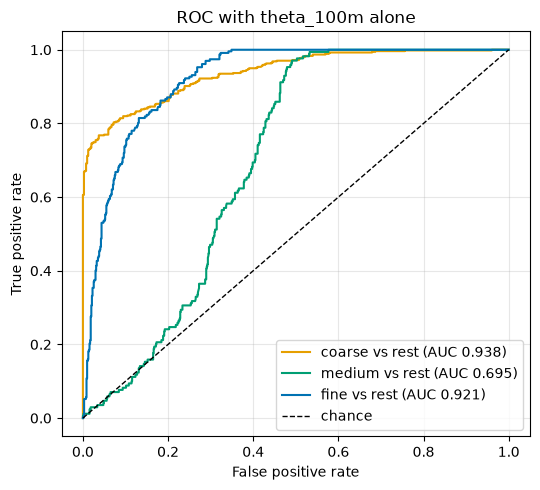

In [22]:
test_scores = dataset["theta_100m"].values
test_is_fine = (dataset["texture_group"] == "fine").values
fpr_check, tpr_check = roc_points(test_scores, test_is_fine)
print("manual AUC:", round(auc_trapezoid(fpr_check, tpr_check), 6),
      "| roc_auc_score:", round(roc_auc_score(test_is_fine, test_scores), 6))

plt.figure(figsize=(5.5, 5))
for group in group_order:
    is_group = (dataset["texture_group"] == group).values
    sign = 1 if test_scores[is_group].mean() > test_scores[~is_group].mean() else -1
    fpr, tpr = roc_points(sign * test_scores, is_group)
    plt.plot(fpr, tpr, color=group_colors[group], label=group + " vs rest (AUC " + str(round(auc_trapezoid(fpr, tpr), 3)) + ")")
plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC with theta_100m alone")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Split by site

A site (`profile_id`) can have several curves from the same soil profile. These curves are very similar to each other (the layers of one profile can still differ in texture: 77 of the 270 sites have more than one group). If a random split sent some of them to training and others to test, I would test the model on soils it has almost seen. The performance would be too optimistic. So I split by site. I shuffle the site identifiers with a fixed seed (`RandomState`, so the result is reproducible) and send 30% of them to the test set. Every curve follows its site. The test curves come from sites the model never saw.

`split_by_site` returns a boolean mask over the curves: `True` for the test set.

In [23]:
def split_by_site(table, test_fraction, seed):
    rng = np.random.RandomState(seed)
    sites = table["profile_id"].unique()
    shuffled = rng.permutation(sites)
    test_sites = shuffled[:int(round(test_fraction * len(sites)))]
    return table["profile_id"].isin(test_sites).values


test_mask = split_by_site(dataset, test_fraction=0.3, seed=42)
train, test = dataset[~test_mask], dataset[test_mask]

print("train:", len(train), "curves from", train["profile_id"].nunique(), "sites")
print("test: ", len(test), "curves from", test["profile_id"].nunique(), "sites")
print("sites shared between train and test:", len(set(train["profile_id"]) & set(test["profile_id"])))
print(pd.DataFrame({"train": train["texture_group"].value_counts()[group_order],
                    "test": test["texture_group"].value_counts()[group_order]}))

train: 645 curves from 189 sites
test:  295 curves from 81 sites
sites shared between train and test: 0
               train  test
texture_group             
coarse           359   179
medium           124    46
fine             162    70


The split has 189 sites for training (645 curves) and 81 for testing (295 curves). No site is in both. The test set keeps the three groups: 179 coarse, 46 medium and 70 fine curves. Always answering *coarse* would give $179/295 = 60.7\%$ accuracy. This is the number any model has to beat.

## Nearest-centroid classifier with all features

The model uses all features together. It is a class with the same `fit` / `predict` pattern as the classes of the course:

1. `fit` standardizes every feature with the mean and standard deviation of the training curves, so no feature dominates because of its units. Then it stores, for each texture group, the average standardized vector: its centroid.
2. `scores` computes, in a loop over the centroids, the Euclidean distance from every curve to each centroid. It returns the distance with the sign changed, so a larger score means "closer", which is what the ROC needs.
3. `predict` assigns each curve to the group of the closest centroid.

I standardize the test curves with the mean and standard deviation of the training curves, never with their own. So nothing from the test set leaks into the model.

In [24]:
class NearestCentroidClassifier:
    def fit(self, X, y, classes):
        self.mean = X.mean(axis=0)
        self.std = X.std(axis=0)
        Z = (X - self.mean) / self.std
        self.classes = np.array(classes)
        self.centroids = np.array([Z[y == c].mean(axis=0) for c in self.classes])
        return self

    def scores(self, X):
        Z = (X - self.mean) / self.std
        distances = np.zeros((len(Z), len(self.centroids)))
        for i, centroid in enumerate(self.centroids):
            distances[:, i] = np.sqrt(((Z - centroid) ** 2).sum(axis=1))
        return -distances

    def predict(self, X):
        return self.classes[np.argmax(self.scores(X), axis=1)]

accuracy: 0.78 | accuracy of always predicting the majority class: 0.607
macro F1: 0.711


,support,recall (Se),specificity (Sp),precision (PPV),F1
coarse,179,0.821,0.879,0.913,0.865
medium,46,0.500,0.847,0.377,0.430
fine,70,0.857,0.942,0.822,0.839


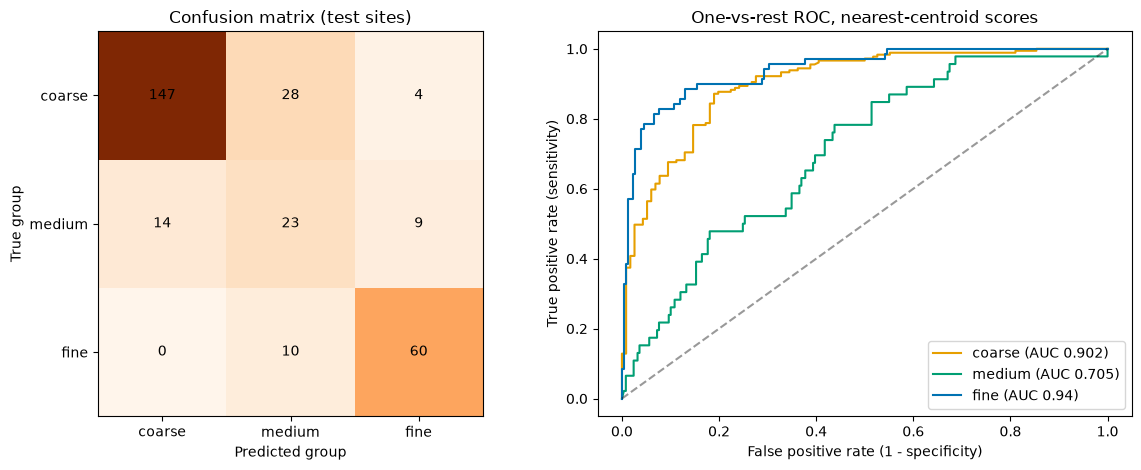

macro AUC: 0.849


In [25]:
X_train, X_test = train[feature_cols].values, test[feature_cols].values
y_train, y_test = train["texture_group"].values, test["texture_group"].values

model = NearestCentroidClassifier().fit(X_train, y_train, group_order)
y_pred = model.predict(X_test)

matrix = confusion_counts(y_test, y_pred, group_order)
accuracy = np.trace(matrix) / matrix.sum()
majority_accuracy = max(np.mean(y_test == c) for c in group_order)
class_table = per_class_metrics(matrix, group_order)

print("accuracy:", round(accuracy, 3), "| accuracy of always predicting the majority class:", round(majority_accuracy, 3))
print("macro F1:", round(class_table["F1"].mean(), 3))
display(class_table.round(3))

scores = model.scores(X_test)
auc_values = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].imshow(matrix, cmap="Oranges")
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(group_order)
axes[0].set_yticks(range(3))
axes[0].set_yticklabels(group_order)
axes[0].set_xlabel("Predicted group")
axes[0].set_ylabel("True group")
axes[0].set_title("Confusion matrix (test sites)")
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, str(matrix[i, j]), ha="center", va="center")

for i, group in enumerate(group_order):
    fpr, tpr = roc_points(scores[:, i], y_test == group)
    auc_value = auc_trapezoid(fpr, tpr)
    auc_values.append(auc_value)
    axes[1].plot(fpr, tpr, color=group_colors[group], label=group + " (AUC " + str(round(auc_value, 3)) + ")")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set_xlabel("False positive rate (1 - specificity)")
axes[1].set_ylabel("True positive rate (sensitivity)")
axes[1].set_title("One-vs-rest ROC, nearest-centroid scores")
axes[1].legend()
plt.tight_layout()
plt.show()

print("macro AUC:", round(np.mean(auc_values), 3))

With all 13 features the classifier reaches an accuracy of 0.78 on the 81 test sites. The trivial answer "always coarse" gives 0.607. The macro F1 is 0.711 and the macro AUC is 0.849.

The confusion matrix shows where the errors are. Coarse and fine are almost never confused with each other: 4 coarse curves are predicted as fine, and no fine curve is predicted as coarse. Nearly all mistakes involve the medium group. Of the 46 medium curves, only 23 are recognized (recall 0.50), 14 go to coarse and 9 to fine. Also, 28 coarse and 10 fine curves are wrongly called medium, so only 38% of the curves predicted as medium are correct (precision 0.38). This is the same picture as in the statistical analysis: the medium group is the bridge between the other two, and it is the hardest.

In the ROC panel, the AUC of the medium group (0.705) is lower than the one of coarse (0.902) and fine (0.940). It is also not higher than the best single feature for medium ($n$, 0.757 in the separability table). The distance to a centroid is a one-sided score, so it cannot isolate a middle group well.

## Which feature domains matter? 30 random site-wise splits

A single split depends on which sites land in the test set. I repeat it 30 times (seeds 0 to 29) to get a mean and a spread. For each feature set I train the classifier on the training sites and measure accuracy and macro F1 on the test sites. `evaluate_features` does one experiment. The table and the figure compare the feature sets. The dashed line is the accuracy of the trivial "always coarse" answer (56.4% on average over the splits).

In [26]:
def evaluate_features(columns, test_mask):
    train_part = dataset[~test_mask]
    test_part = dataset[test_mask]
    model = NearestCentroidClassifier().fit(train_part[columns].values, train_part["texture_group"].values, group_order)
    y_true = test_part["texture_group"].values
    y_pred = model.predict(test_part[columns].values)

    matrix = confusion_counts(y_true, y_pred, group_order)
    class_table = per_class_metrics(matrix, group_order)
    accuracy = np.trace(matrix) / matrix.sum()
    baseline = max(np.mean(y_true == c) for c in group_order)
    return accuracy, class_table["F1"].mean(), baseline


candidate_sets = dict(domains)
candidate_sets["all features"] = feature_cols

repeat = {"feature set": [], "seed": [], "accuracy": [], "macro F1": [], "majority baseline": []}
for set_name, columns in candidate_sets.items():
    for seed in range(30):
        mask = split_by_site(dataset, test_fraction=0.3, seed=seed)
        accuracy, macro_f1, baseline = evaluate_features(columns, mask)
        repeat["feature set"].append(set_name)
        repeat["seed"].append(seed)
        repeat["accuracy"].append(accuracy)
        repeat["macro F1"].append(macro_f1)
        repeat["majority baseline"].append(baseline)

repeat = pd.DataFrame(repeat)
summary = repeat.groupby("feature set")[["accuracy", "macro F1", "majority baseline"]].agg(["mean", "std"])
summary = summary.loc[list(candidate_sets.keys())]
summary.round(3)

accuracy        macro F1        majority baseline  \
                             mean    std     mean    std              mean   
feature set                                                                  
retention level             0.684  0.036    0.613  0.031             0.564   
curve shape                 0.579  0.038    0.522  0.039             0.564   
van Genuchten parameters    0.700  0.040    0.671  0.036             0.564   
all features                0.753  0.031    0.705  0.031             0.564   

                                 
                            std  
feature set                      
retention level           0.042  
curve shape               0.042  
van Genuchten parameters  0.042  
all features              0.042

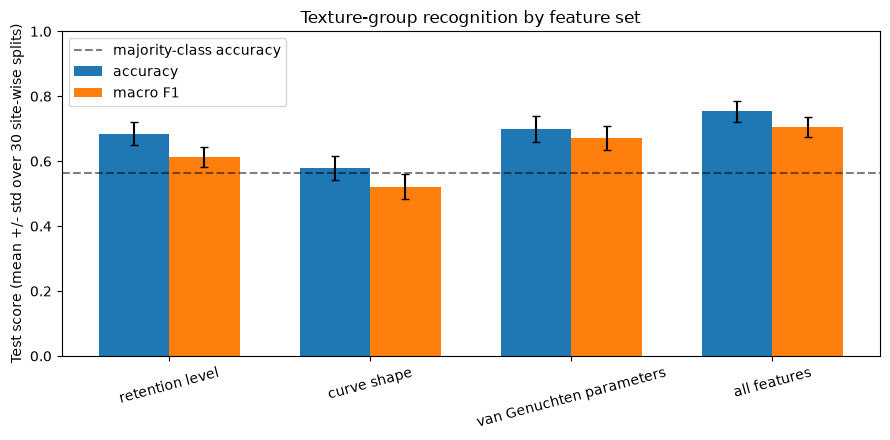

In [27]:
means = summary.xs("mean", axis=1, level=1)[["accuracy", "macro F1"]]
stds = summary.xs("std", axis=1, level=1)[["accuracy", "macro F1"]]

positions = np.arange(len(means))
width = 0.35

plt.figure(figsize=(9, 4.5))
for k, metric in enumerate(means.columns):
    plt.bar(positions + (k - 0.5) * width, means[metric], width, yerr=stds[metric], capsize=3, label=metric)
plt.axhline(repeat["majority baseline"].mean(), color="k", linestyle="--", alpha=0.5, label="majority-class accuracy")
plt.xticks(positions, means.index, rotation=15)
plt.ylim(0, 1)
plt.ylabel("Test score (mean +/- std over 30 site-wise splits)")
plt.title("Texture-group recognition by feature set")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

The standard deviations are about 0.03 to 0.04, so I do not read small differences.

- All 13 features together have the highest accuracy (0.753) and macro F1 (0.705). Both are well above the trivial 0.564.
- Retention level alone has an accuracy of 0.684 and a macro F1 of 0.613. The van Genuchten parameters, with only 4 features, have an accuracy of 0.700 and a macro F1 of 0.671.
- Curve shape alone is not better than the trivial answer (accuracy 0.579, macro F1 0.522).

For the thesis: the amount of water held separates coarse and fine soils well, and no feature set separates the three groups well. So texture should be an input of the future model. I did not compute results per class for each feature set, so I cannot say which domain helps most with the medium group.

## Discussion

What the data shows. After cleaning, 940 tropical curves from 270 sites were left (from 15,259). The water held at reference potentials is the most informative family of features. $\theta_{100m}$ alone separates coarse from the rest with an AUC of 0.94, and fine with 0.92. Medium is a transition class that overlaps with both. No single feature gets its AUC above 0.76, and almost all errors of the classifier involve it. Using all features helps (macro F1 0.705 against 0.613 for the retention level alone), and curve shape is weak by itself.

What it means for the thesis. The curves of the three texture groups are different, so one calibration cannot map the same electromagnetic response to matric potential for all soils. The future model needs texture, or an equivalent descriptor, as an input, as the thesis proposes. The code has one extractor class per domain, so I can add a new domain (for example a spectral one) when real signals exist.

Limitations:

- The three texture groups are my own grouping of USDA classes. Merging classes hides variation inside each group, and medium is the least homogeneous.
- Texture and source are linked. Grunwald_2020 has 445 coarse curves out of 499, and Ottoni_et_al_2018 has 175 fine curves out of 234 (table in the overview). The classifier may learn part of the differences between sources, and I did not test this.
- The `data_flag` filter keeps the curves where the published fit was well defined. This can change the class mix, and I did not measure it.
- The curves have about ten points, so the interpolated curve is piecewise linear and the shape features are coarse and partly discrete.
- In 16% of the fits $\theta_r$ ended on its lower bound, and 45% of the medium curves are in this case. So $\theta_r$ is partly an artifact of the measured range, and it can make medium look more different than it is.
- The p-values assume independent curves, but several curves come from the same site.
- The classifier is simple on purpose (only what we saw in class). It uses means and standard deviations, which are sensitive to outliers, and it ignores the correlation between features.
- One source, Grunwald_2020, has 53% of the curves, only tropical soils were used, and there is no electromagnetic signal yet because the sensor has not been built.

## Conclusions

I cleaned a public dataset with documented criteria and restructured it into one row per curve. I extracted three feature domains with a small class hierarchy. I compared the groups with rank-based tests chosen after checking normality, and I measured separability with Fisher's ratio, AUC and classification metrics.

Two results stand out. First, the water held at reference potentials separates coarse from fine soils well (AUC above 0.9), but not the medium group (best single-feature AUC 0.76). Second, using the three domains together gives an accuracy of 0.753 and a macro F1 of 0.705 on unseen sites (mean of 30 splits), against 0.564 for the trivial answer. This pipeline is the base I will reuse when real electromagnetic measurements exist.

# References

- Gupta, S., Papritz, A., Lehmann, P., Hengl, T., Bonetti, S., & Or, D. (2022). Global Soil Hydraulic Properties dataset based on legacy site observations and robust parameterization. *Scientific Data*, 9, 444. https://doi.org/10.1038/s41597-022-01481-5
- Marusteri, M., & Bacarea, V. (2010). Comparing groups for statistical differences: how to choose the right statistical test? *Biochemia Medica*, 20(1), 15-32.
- van Genuchten, M. T. (1980). A closed-form equation for predicting the hydraulic conductivity of unsaturated soils. *Soil Science Society of America Journal*, 44(5), 892-898. https://doi.org/10.2136/sssaj1980.03615995004400050002x